## 1. Find SUMO

In [12]:
import os, sys, shutil, random, pickle
from collections import defaultdict
from dotenv import find_dotenv, load_dotenv

# Load machine-specific settings (SUMO_HOME, SUMO_FOLDER) from a local .env file, if there is one
load_dotenv(find_dotenv(usecwd=True))

SUMO_HOME = os.environ.get("SUMO_HOME")
if not SUMO_HOME:
    try:
        import sumo
        SUMO_HOME = getattr(sumo, "SUMO_HOME", None)
    except ImportError:
        pass
if not SUMO_HOME and shutil.which("sumo"):
    SUMO_HOME = os.path.dirname(os.path.dirname(os.path.realpath(shutil.which("sumo"))))
if SUMO_HOME:
    os.environ["SUMO_HOME"] = SUMO_HOME
    sys.path.append(os.path.join(SUMO_HOME, "tools"))
import traci

def sumo_binary(name):
    if SUMO_HOME:
        for candidate in (name, name + ".exe"):
            path = os.path.join(SUMO_HOME, "bin", candidate)
            if os.path.exists(path):
                return path
    return shutil.which(name) or name

print("SUMO_HOME:", SUMO_HOME)

SUMO_HOME: /opt/anaconda3/envs/platooning/lib/python3.12/site-packages/sumo


## 2. Settings

In [ ]:
FOLDER = os.environ.get("SUMO_FOLDER", ".")    # folder with the SUMO files (set in .env)

SCENARIO = "osm"            # "example" = 600 m test road, "osm" = road exported from OpenStreetMap
if SCENARIO == "example":
    CONFIG_FILE = os.path.join(FOLDER, "accident.sumocfg")
    EDGE = "highway"
    CRASH_POSITION = 300.0   # m, where the accident happens (road is 600 m)
    AGENT_PREFIX = "cars"    # agents are picked from the vehicles of this flow
    EPISODE_END = 450.0      # s, length of one episode
else:
    FOLDER = os.path.join(FOLDER, "scenarios", "2026-10-29-23-52-03")
    CONFIG_FILE = os.path.join(FOLDER, "osm.sumocfg")
    EDGE = "1229067689#1"    # direction A: one straight 1797 m edge (the accident side)
    CRASH_POSITION = 900.0  # m from the start of the edge
    AGENT_PREFIX = "car_A"   # only direction A cars; direction B never reaches the accident
    EPISODE_END = 600.0      # s, same as SIM_END in the accident notebook

# --- Scenario ---
CRASH_VEHICLE, HIT_VEHICLE = "crash_car", "hit_car"
HIT_SPEED = 12.0             # m/s
ACCIDENT_DURATION = 300.0    # s
STEP_LENGTH = 0.5            # s, simulation step during training (faster than 0.1)

# --- Agents ---
P_SMART = 0.3                # share of cars that are learning agents
DECISION_INTERVAL = 1.0      # s between decisions
JOIN_RANGE = 50.0            # m, max gap to the vehicle ahead to join a platoon
PLATOON_TAU = 0.5            # s, time gap inside a platoon (normal cars: 1.0 s)

# --- Reward ---
W_LOCAL, W_GLOBAL = 0.5, 0.5
V_MAX = 33.33                # m/s, to normalise speed
GLOBAL_NORM = 2.0            # vehicles leaving per decision interval that counts as "1"
UNSAFE_GAP = 2.0             # m
PENALTY_UNSAFE, PENALTY_COLLISION = 1.0, 5.0

# --- Q-learning ---
N_EPISODES = 40
ALPHA, GAMMA = 0.1, 0.95
EPS_START, EPS_END = 1.0, 0.05

ACTIONS = ["keep", "slow", "join", "leave", "left"]
print(f"{CONFIG_FILE:40s}", "OK" if os.path.exists(CONFIG_FILE) else "MISSING")

/Users/hubertkrzemieniewski/Documents/university/year4/final-year-project/sumo_accident/scenarios/2026-10-29-23-52-03/osm.sumocfg OK


## 3. Accident (same logic as the accident notebook)

In [14]:
def new_accident():
    return {"crash_time": None, "hit_armed": False, "hit_done": False, "cleared": False}

def accident_step(acc, t, ids):
    """Advance the accident by one simulation step."""
    if not acc["cleared"]:
        for v in (CRASH_VEHICLE, HIT_VEHICLE):
            if v in ids:
                traci.vehicle.setLaneChangeMode(v, 0)

    if acc["crash_time"] is None and CRASH_VEHICLE in ids:
        if traci.vehicle.getLanePosition(CRASH_VEHICLE) >= CRASH_POSITION:
            traci.vehicle.setDecel(CRASH_VEHICLE, 9.0)
            traci.vehicle.setSpeed(CRASH_VEHICLE, 0.0)
            traci.vehicle.setColor(CRASH_VEHICLE, (255, 0, 0, 255))
            acc["crash_time"] = t

    if acc["crash_time"] is not None and not acc["hit_armed"] and HIT_VEHICLE in ids:
        traci.vehicle.setSpeedMode(HIT_VEHICLE, 0)
        traci.vehicle.setSpeed(HIT_VEHICLE, HIT_SPEED)
        traci.vehicle.setColor(HIT_VEHICLE, (255, 140, 0, 255))
        acc["hit_armed"] = True

    if acc["hit_armed"] and not acc["hit_done"] and HIT_VEHICLE in ids and CRASH_VEHICLE in ids:
        rear = traci.vehicle.getLanePosition(CRASH_VEHICLE) - traci.vehicle.getLength(CRASH_VEHICLE)
        gap = rear - traci.vehicle.getLanePosition(HIT_VEHICLE)
        if -1.0 < gap <= traci.vehicle.getSpeed(HIT_VEHICLE) * traci.simulation.getDeltaT() + 0.3:
            traci.vehicle.setSpeed(HIT_VEHICLE, 0.0)
            traci.vehicle.setColor(HIT_VEHICLE, (255, 0, 0, 255))
            acc["hit_done"] = True

    if acc["crash_time"] is not None and not acc["cleared"] and t >= acc["crash_time"] + ACCIDENT_DURATION:
        for v in (CRASH_VEHICLE, HIT_VEHICLE):
            if v in ids:
                traci.vehicle.setSpeed(v, -1)
                traci.vehicle.setSpeedMode(v, 31)
                traci.vehicle.setLaneChangeMode(v, 1621)
        acc["cleared"] = True

def accident_active(acc):
    return acc["crash_time"] is not None and not acc["cleared"]

## 4. State, actions, reward, Q-table

In [15]:
CYAN, PURPLE = (0, 200, 255, 255), (170, 60, 255, 255)

def leader_gap(v):
    leader = traci.vehicle.getLeader(v, 100.0)
    if leader is None or leader[0] == "":
        return None
    return leader[1]

def get_state(v, acc, in_platoon):
    pos = traci.vehicle.getLanePosition(v)
    speed = traci.vehicle.getSpeed(v)
    gap = leader_gap(v)
    active = accident_active(acc)

    if not active:
        dist_bin = 3                                   # no accident right now
    else:
        d = CRASH_POSITION - pos
        dist_bin = 0 if d < 50 else (1 if d < 150 else 2)
    blocked = int(active and traci.vehicle.getLaneIndex(v) == 0)
    speed_bin = 0 if speed < 5 else (1 if speed < 15 else (2 if speed < 25 else 3))
    gap_bin = 0 if gap is None or gap > 50 else (1 if gap > 20 else 2)
    return (dist_bin, blocked, speed_bin, gap_bin, int(in_platoon))

def choose_action(Q, s, epsilon):
    if random.random() < epsilon:
        return random.randrange(len(ACTIONS))
    values = Q[s]
    best = max(values)
    return random.choice([a for a, q in enumerate(values) if q == best])

def apply_action(v, a, platoon):
    name = ACTIONS[a]
    if name == "keep":
        traci.vehicle.setSpeed(v, -1)
    elif name == "slow":
        traci.vehicle.setSpeed(v, max(traci.vehicle.getSpeed(v) - 3.0, 3.0))
    elif name == "join":
        traci.vehicle.setSpeed(v, -1)
        gap = leader_gap(v)
        if v not in platoon and gap is not None and gap < JOIN_RANGE:
            traci.vehicle.setType(v, "car_platoon")
            traci.vehicle.setColor(v, PURPLE)
            platoon.add(v)
    elif name == "leave":
        traci.vehicle.setSpeed(v, -1)
        if v in platoon:
            traci.vehicle.setType(v, "car")
            traci.vehicle.setColor(v, CYAN)
            platoon.discard(v)
    elif name == "left":             # move out of the blocked lane 0 into lane 1
        traci.vehicle.setSpeed(v, -1)
        if traci.vehicle.getLaneIndex(v) == 0:
            traci.vehicle.changeLane(v, 1, 3.0)

def get_reward(v, arrived_in_interval, colliding):
    speed = traci.vehicle.getSpeed(v)
    gap = leader_gap(v)
    r = W_LOCAL * speed / V_MAX + W_GLOBAL * arrived_in_interval / GLOBAL_NORM
    if gap is not None and gap < UNSAFE_GAP:
        r -= PENALTY_UNSAFE
    if v in colliding:
        r -= PENALTY_COLLISION
    return r

def q_update(Q, s, a, r, s_next):
    target = r if s_next is None else r + GAMMA * max(Q[s_next])
    Q[s][a] += ALPHA * (target - Q[s][a])

def new_q_table():
    return defaultdict(lambda: [0.0] * len(ACTIONS))

## 5. One episode

`control=False` = baseline: the same vehicles are marked as agents but nobody controls them (no platooning).

In [16]:
def run_episode(Q, epsilon, seed, learn=True, control=True, use_gui=False, gui_delay=100):
    random.seed(seed)
    binary = sumo_binary("sumo-gui" if use_gui else "sumo")
    cmd = [binary, "-c", CONFIG_FILE, "--start", "--seed", str(seed),
           "--collision.action", "warn", "--no-warnings", "true"]
    if use_gui:
        cmd += ["--delay", str(gui_delay)]
    else:
        cmd += ["--step-length", str(STEP_LENGTH)]
    traci.start(cmd)

    # platoon vehicle type = a copy of "car" with a short time gap
    traci.vehicletype.copy("car", "car_platoon")
    traci.vehicletype.setTau("car_platoon", PLATOON_TAU)
    traci.vehicletype.setMinGap("car_platoon", 1.5)

    acc = new_accident()
    smart, platoon = set(), set()
    memory = {}                     # agent -> (state, action) of its last decision
    depart_time, travel_times = {}, []  # only vehicles that start on EDGE are measured
    arrived_in_interval, collisions = 0, 0
    next_decision = DECISION_INTERVAL
    total_reward = 0.0

    try:
        while traci.simulation.getTime() < EPISODE_END:
            traci.simulationStep()
            t = traci.simulation.getTime()
            ids = set(traci.vehicle.getIDList())

            for v in traci.simulation.getDepartedIDList():
                if traci.vehicle.getRoadID(v) != EDGE:
                    continue
                depart_time[v] = t
                if v.startswith(AGENT_PREFIX) and random.random() < P_SMART:
                    smart.add(v)
                    traci.vehicle.setColor(v, CYAN)
            for v in traci.simulation.getArrivedIDList():
                if v in depart_time:
                    arrived_in_interval += 1
                    travel_times.append(t - depart_time[v])
                memory.pop(v, None)

            colliding = set(traci.simulation.getCollidingVehiclesIDList()) - {CRASH_VEHICLE, HIT_VEHICLE}
            collisions += len(colliding & smart)

            accident_step(acc, t, ids)

            if control and t + 1e-6 >= next_decision:
                for v in smart & ids:
                    in_zone = traci.vehicle.getLanePosition(v) < CRASH_POSITION
                    s = get_state(v, acc, v in platoon) if in_zone else None
                    if v in memory and learn:
                        r = get_reward(v, arrived_in_interval, colliding)
                        q_update(Q, *memory[v], r, s)
                        total_reward += r
                    if in_zone:
                        a = choose_action(Q, s, epsilon)
                        apply_action(v, a, platoon)
                        memory[v] = (s, a)
                    elif v in memory:            # passed the accident site: hand back control
                        traci.vehicle.setSpeed(v, -1)
                        memory.pop(v)
                arrived_in_interval = 0
                next_decision += DECISION_INTERVAL
    finally:
        traci.close()

    return {
        "arrived": len(travel_times),
        "mean_travel_time": sum(travel_times) / max(len(travel_times), 1),
        "collisions": collisions,
        "total_reward": total_reward,
    }

## 6. Train

In [17]:
Q = new_q_table()
history = []

for ep in range(N_EPISODES):
    epsilon = max(EPS_END, EPS_START - (EPS_START - EPS_END) * ep / (0.7 * N_EPISODES))
    result = run_episode(Q, epsilon, seed=ep)
    result.update(episode=ep, epsilon=epsilon, states_seen=len(Q))
    history.append(result)
    print(f"episode {ep:3d} | eps {epsilon:4.2f} | arrived {result['arrived']:4d} | "
          f"travel time {result['mean_travel_time']:6.1f} s | collisions {result['collisions']} | "
          f"reward {result['total_reward']:8.1f} | states {len(Q)}")

with open(os.path.join(FOLDER, "q_table.pkl"), "wb") as f:
    pickle.dump(dict(Q), f)

 Retrying in 1 seconds
***Starting server on port 52266 ***
Loading net-file from '/Users/hubertkrzemieniewski/Documents/university/year4/final-year-project/sumo_accident/scenarios/2026-10-29-23-52-03/road.net.xml' ... done (6ms).
Loading route-files incrementally from '/Users/hubertkrzemieniewski/Documents/university/year4/final-year-project/sumo_accident/scenarios/2026-10-29-23-52-03/routes.rou.xml'
Loading done.
Simulation version 1.28.0 started with time: 0.00.
Simulation ended at time: 900.00.
Reason: TraCI requested termination.
Performance:
 Duration: 1.32s
 TraCI-Duration: 1.14s
 Real time factor: 684.411
 UPS: 66106.463878
Vehicles:
 Inserted: 694
 Running: 0
 Waiting: 0
 Teleports: 0 (Collisions: 1)
 Emergency Braking: 2
Statistics (avg of 694):
 RouteLength: 1787.80
 Speed: 29.59
 Duration: 62.63
 WaitingTime: 1.62
 TimeLoss: 5.65
 DepartDelay: 0.22
DijkstraRouter answered 346 queries and explored 3.00 edges on average.
DijkstraRouter spent 0.00s answering queries (0.00ms on

## 7. Learning curve

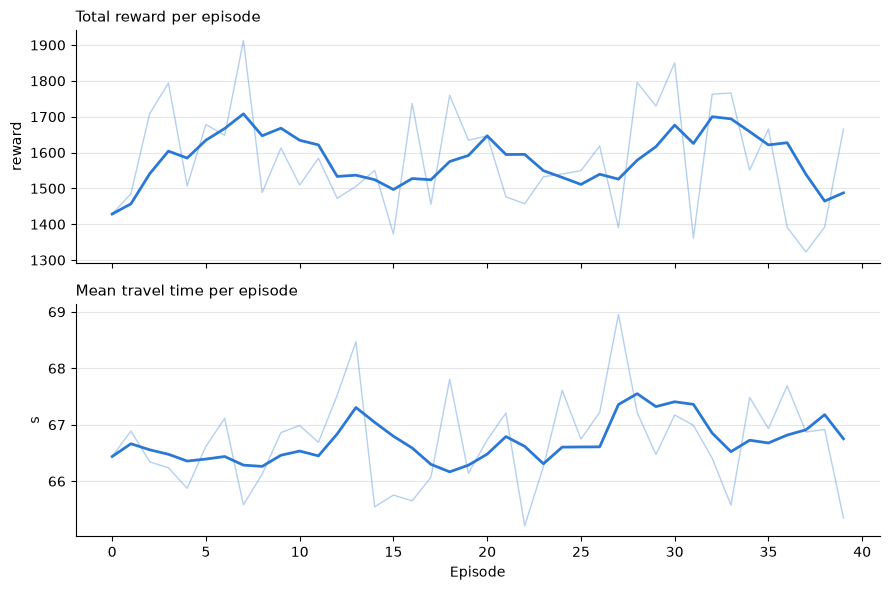

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

hist = pd.DataFrame(history)
BLUE = "#2a78d6"
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for ax, col, title, unit in [(axes[0], "total_reward", "Total reward per episode", "reward"),
                             (axes[1], "mean_travel_time", "Mean travel time per episode", "s")]:
    ax.plot(hist["episode"], hist[col], color=BLUE, linewidth=1, alpha=0.35)
    ax.plot(hist["episode"], hist[col].rolling(5, min_periods=1).mean(), color=BLUE, linewidth=2)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_ylabel(unit)
    ax.grid(axis="y", color="0.9")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[1].set_xlabel("Episode")
plt.tight_layout()
plt.show()

## 8. Evaluate: baseline vs learned policy

Same seeds for both. Baseline = no control (no platooning). Learned = greedy policy (epsilon = 0, no learning).

In [19]:
EVAL_SEEDS = [1000, 1001, 1002, 1003, 1004]
rows = []
for seed in EVAL_SEEDS:
    for name, control in [("Baseline (no control)", False), ("Q-learning platooning", True)]:
        r = run_episode(Q, epsilon=0.0, seed=seed, learn=False, control=control)
        r.update(method=name, seed=seed)
        rows.append(r)

ev = pd.DataFrame(rows)
summary = ev.groupby("method")[["arrived", "mean_travel_time", "collisions"]].agg(["mean", "std"]).round(1)
summary

 Retrying in 1 seconds
***Starting server on port 52454 ***
Loading net-file from '/Users/hubertkrzemieniewski/Documents/university/year4/final-year-project/sumo_accident/scenarios/2026-10-29-23-52-03/road.net.xml' ... done (4ms).
Loading route-files incrementally from '/Users/hubertkrzemieniewski/Documents/university/year4/final-year-project/sumo_accident/scenarios/2026-10-29-23-52-03/routes.rou.xml'
Loading done.
Simulation version 1.28.0 started with time: 0.00.
Simulation ended at time: 900.00.
Reason: TraCI requested termination.
Performance:
 Duration: 0.57s
 TraCI-Duration: 0.42s
 Real time factor: 1592.92
 UPS: 154267.256637
Vehicles:
 Inserted: 694
 Running: 0
 Waiting: 0
 Emergency Braking: 2
Statistics (avg of 694):
 RouteLength: 1787.80
 Speed: 29.69
 Duration: 62.80
 WaitingTime: 1.95
 TimeLoss: 6.16
 DepartDelay: 0.22
DijkstraRouter answered 346 queries and explored 3.00 edges on average.
DijkstraRouter spent 0.00s answering queries (0.00ms on average).
 Retrying in 1 sec

arrived      mean_travel_time      collisions     
                         mean  std             mean  std       mean  std
method                                                                  
Baseline (no control)   348.0  0.0             66.0  0.8        0.0  0.0
Q-learning platooning   348.0  0.0             65.6  0.9        0.0  0.0

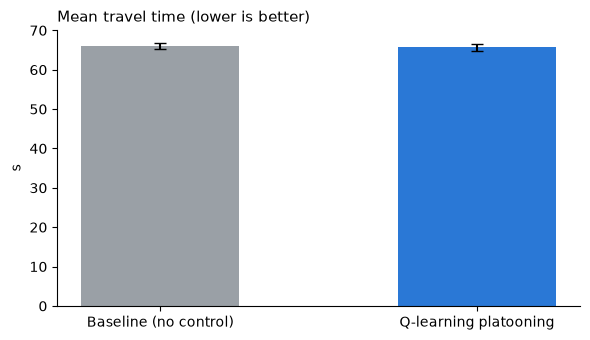

In [20]:
means = ev.groupby("method")["mean_travel_time"].mean()
stds = ev.groupby("method")["mean_travel_time"].std()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(means.index, means.values, yerr=stds.values, color=["#9aa0a6", BLUE], width=0.5, capsize=4)
ax.set_title("Mean travel time (lower is better)", loc="left", fontsize=11)
ax.set_ylabel("s")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

## 9. Watch the learned policy (optional)

Light blue = agent, purple = agent in platoon mode, red = accident.

In [21]:
WATCH = False
if WATCH:
    run_episode(Q, epsilon=0.0, seed=2000, learn=False, control=True, use_gui=True, gui_delay=100)

## 10. Look inside the Q-table (optional)
Best action for each visited state. State = (distance bin, in blocked lane, speed bin, gap bin, in platoon).

In [22]:
policy = pd.DataFrame(
    [{"state": s, "best_action": ACTIONS[max(range(len(ACTIONS)), key=lambda a: q[a])],
      **{a: round(q[i], 2) for i, a in enumerate(ACTIONS)}} for s, q in Q.items()]
).sort_values("state")
policy

,state,best_action,keep,slow,join,leave,left
105,"(0, 0, 0, 1, 0)",leave,0.00,0.00,0.00,0.01,0.00
91,"(0, 0, 0, 1, 1)",left,0.00,0.00,0.03,0.00,0.05
58,"(0, 0, 0, 2, 0)",left,0.11,0.12,0.09,0.01,0.28
60,"(0, 0, 0, 2, 1)",join,0.06,0.00,0.13,0.07,0.01
83,"(0, 0, 1, 0, 0)",slow,0.00,0.15,0.00,0.00,0.04
...,...,...,...,...,...,...,...
3,"(3, 0, 3, 0, 1)",leave,6.74,6.57,6.77,7.09,6.41
1,"(3, 0, 3, 1, 0)",join,5.29,5.70,6.65,5.36,5.63
2,"(3, 0, 3, 1, 1)",left,5.99,5.91,5.95,5.93,6.13
56,"(3, 0, 3, 2, 0)",slow,1.61,6.73,2.44,0.78,3.14
